# Live coding 01 · From gradients to a trained network in PyTorch

The coach's notebook for lecture sections 6–8 (gradient descent and optimizers · the training loop ·
generalization and debugging), plus a short bridge to the inversion task.

* Run it **cell by cell**. The saved outputs are the numbers to expect (CPU, one thread; another machine may differ in the 3rd decimal).
* At every **PREDICT** cell, stop and take a public vote, then run the next cell.
* Parts 3–8 use the same code and the same names as the section-7 slides (`X_tr`, `y_tr`, `X_va`, `y_va`, `.unsqueeze(1)`, the `perm` loop).
* Planned mistakes: **1** no input scaling (part 4) · **2** no `zero_grad` (part 6) · **3** Sigmoid + `BCEWithLogitsLoss`, the cliffhanger (part 7) · **4** target shape (part 8).
* The whole notebook runs in one to two minutes on a laptop CPU.
* **Colab:** upload `data_train.csv` in the Files panel and set `DATA_DIR = "."` in the first code cell.

| Part | What | Lecture |
|---|---|---|
| 0 | Setup and seed | |
| 1 | Tensors, layers, shapes; the 2-8-8-1 has 105 parameters | §2 recap |
| 2 | Gradient descent by hand, then with `torch.optim` | §6 |
| 3 | Kobe's shots: shapes, base rate, train/validation split | §7 |
| 4 | Planned mistake 1: no input scaling | §7.4 |
| 5 | The model, the five-beat loop, evaluation, baselines, pictures | §7.5–7.6, §7.11 |
| 6 | Planned mistake 2: no `zero_grad` | §7.7 |
| 7 | Planned mistake 3: Sigmoid + `BCEWithLogitsLoss` (cliffhanger reveal) | §7.8 |
| 8 | Planned mistake 4: target shape `(N,)` vs `(N, 1)` | §7.9 |
| 9 | Optimizer comparison on Kobe | §6.10 |
| 10 | Overfitting and early stopping | §8.2–8.4 |
| 11 | Optimise the input, not the weights: bridge to the inversion task | §9.8–9.10 |

## Part 0 · Setup

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Colab: upload data_train.csv in the Files panel and use DATA_DIR = "."
DATA_DIR = "../data/kobe"

# tiny networks run fastest on one thread
torch.set_num_threads(1)
# same seed -> same initial weights -> the same numbers as below
torch.manual_seed(0)
print(torch.__version__)

2.15.0+cpu


## Part 1 · Tensors, layers and shapes

A layer is a matrix multiply applied to a whole batch at once.

**PREDICT:** `nn.Linear(2, 8)` on a batch of 32 shots. Shape of the output? Shape of `layer.weight`?

In [2]:
layer = nn.Linear(2, 8)            # 2 inputs (x, y) -> 8 neurons
batch = torch.randn(32, 2)         # 32 shots, 2 numbers each
out = layer(batch)

print("batch ", batch.shape)
print("weight", layer.weight.shape, "  <- (out, in), not (in, out)")
print("bias  ", layer.bias.shape)
print("output", out.shape)

batch  torch.Size([32, 2])
weight torch.Size([8, 2])   <- (out, in), not (in, out)
bias   torch.Size([8])
output torch.Size([32, 8])


In [3]:
# nn.Linear is exactly  x @ W.T + b , for all 32 rows at once
by_hand = batch @ layer.weight.T + layer.bias
torch.allclose(by_hand, out)

True

Stack three layers: the 2-8-8-1 MLP from section 2, written as our own `nn.Module`.
Kobe rules: at most 3 linear layers, at most 8 neurons each, activations as modules after linear layers,
**no `nn.Sequential`** (it scores 0). The last layer outputs a **logit**, with no sigmoid: the loss adds it.
This is the `MLP` the section-7 slides use.

In [4]:
class MLP(nn.Module):
    def __init__(self, hidden=8):
        super().__init__()
        # __init__ creates the layers: this is where the weights live
        self.fc1 = nn.Linear(2, hidden)
        self.act1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden, hidden)
        self.act2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden, 1)        # one logit out, no sigmoid

    def forward(self, x):
        # forward says how a batch flows through the layers
        x = self.act1(self.fc1(x))             # (B, 2) -> (B, 8)
        x = self.act2(self.fc2(x))             # (B, 8) -> (B, 8)
        return self.fc3(x)                     # (B, 8) -> (B, 1)

**PREDICT:** how many parameters (weights + biases) does the 2-8-8-1 have?

In [5]:
model = MLP()
for name, p in model.named_parameters():
    print(f"{name:11s} {str(tuple(p.shape)):7s} {p.numel():3d}")
# 24 + 72 + 9
print("total", sum(p.numel() for p in model.parameters()))
print("output for the batch:", model(batch).shape)

fc1.weight  (8, 2)   16
fc1.bias    (8,)      8
fc2.weight  (8, 8)   64
fc2.bias    (8,)      8
fc3.weight  (1, 8)    8
fc3.bias    (1,)      1
total 105
output for the batch: torch.Size([32, 1])


## Part 2 · Gradient descent: by hand, then with `torch.optim`

On paper: L(w) = (w − 3)², w₀ = 0, η = 0.1 → gradient −6 → w₁ = 0.6. Now autograd computes the gradient.
Four new words: `requires_grad` (track this number) · `backward()` (fill `.grad`) ·
`torch.no_grad()` (update without recording) · `grad.zero_()` (clear before the next step).

In [6]:
w = torch.tensor(0.0, requires_grad=True)      # track gradients for w
for step in range(5):
    loss = (w - 3) ** 2
    loss.backward()                            # dL/dw = 2(w - 3), stored in w.grad
    print(f"step {step}: w = {w.item():.4f}   loss = {loss.item():.4f}   "
          f"grad = {w.grad.item():.4f}")
    # the update itself must not be recorded in the graph
    with torch.no_grad():
        w -= 0.1 * w.grad
    # gradients ADD UP, so clear them before the next backward
    w.grad.zero_()
print(f"after 5 steps: w = {w.item():.4f}")

step 0: w = 0.0000   loss = 9.0000   grad = -6.0000
step 1: w = 0.6000   loss = 5.7600   grad = -4.8000
step 2: w = 1.0800   loss = 3.6864   grad = -3.8400
step 3: w = 1.4640   loss = 2.3593   grad = -3.0720
step 4: w = 1.7712   loss = 1.5099   grad = -2.4576
after 5 steps: w = 2.0170


The same thing with an optimizer: the three lines `zero_grad` · `backward` · `step`.

In [7]:
w = torch.tensor(0.0, requires_grad=True)
# the optimizer gets the list of tensors it may change
opt = torch.optim.SGD([w], lr=0.1)
for step in range(5):
    opt.zero_grad()
    loss = (w - 3) ** 2
    loss.backward()
    opt.step()                                 # does  w -= lr * w.grad  for us
print(f"after 5 steps: w = {w.item():.4f}")    # identical to the manual loop

after 5 steps: w = 2.0170


**PREDICT:** learning rates 0.02, 0.3, 0.9 and 1.05. Where is w after 10 steps? (The minimum is at 3.)

In [8]:
for lr in [0.02, 0.3, 0.9, 1.05]:
    w = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.SGD([w], lr=lr)
    path = []
    for step in range(10):
        opt.zero_grad()
        loss = (w - 3) ** 2
        loss.backward()
        opt.step()
        path.append(round(w.item(), 2))
    print(f"lr {lr:<4}  w: {path}")

lr 0.02  w: [0.12, 0.24, 0.35, 0.45, 0.55, 0.65, 0.75, 0.84, 0.92, 1.01]
lr 0.3   w: [1.8, 2.52, 2.81, 2.92, 2.97, 2.99, 3.0, 3.0, 3.0, 3.0]
lr 0.9   w: [5.4, 1.08, 4.54, 1.77, 3.98, 2.21, 3.63, 2.5, 3.4, 2.68]
lr 1.05  w: [6.3, -0.63, 6.99, -1.39, 7.83, -2.31, 8.85, -3.43, 10.07, -4.78]


Too slow · just right · oscillating but converging · diverging. The error is multiplied by (1 − 2·lr) every step.

**PREDICT (P7):** one step of Adam with lr 1e-3 on three weights whose gradients are 1000, 1 and 0.001.
How far does each weight move? And with plain SGD?

In [9]:
grads = torch.tensor([1000.0, 1.0, 0.001])
for opt_class in [torch.optim.SGD, torch.optim.Adam]:
    w = torch.zeros(3, requires_grad=True)
    opt = opt_class([w], lr=1e-3)
    loss = (grads * w).sum()                   # so dL/dw is exactly `grads`
    loss.backward()
    opt.step()
    moves = [f"{v:.6f}" for v in w.tolist()]
    print(f"{opt_class.__name__:4s} moved the weights by {moves}")

SGD  moved the weights by ['-1.000000', '-0.001000', '-0.000001']
Adam moved the weights by ['-0.001000', '-0.001000', '-0.001000']


SGD's step is lr × gradient. Adam's first step is ≈ lr for **every** weight, whatever the gradient's size.

## Part 3 · Kobe's shots

`loc_x`, `loc_y` are in tenths of feet with the rim at (0, 0). They are the **only** allowed inputs
(`shot_distance` is forbidden, and it is just ⌊distance / 10⌋ anyway).

**PREDICT:** what percentage of his shots went in?

In [10]:
df = pd.read_csv(f"{DATA_DIR}/data_train.csv")
print(df.shape)
df.head()

(25000, 6)


,loc_x,loc_y,minutes_remaining,shot_distance,shot_made_flag,shot_id
0,0,0,7,0,1,1
1,-3,130,9,13,0,2
2,82,8,7,8,0,3
3,100,101,10,14,1,4
4,0,0,9,0,1,5


In [11]:
made_rate = df["shot_made_flag"].mean()
print(f"shots made: {made_rate:.1%}")
print(f"so 'always miss' is already {1 - made_rate:.1%} accurate")
df[["loc_x", "loc_y"]].describe().round(1)

shots made: 44.7%
so 'always miss' is already 55.3% accurate


,loc_x,loc_y
count,25000.0,25000.0
mean,7.1,91.3
std,110.0,88.3
min,-250.0,-44.0
25%,-67.2,4.0
50%,0.0,72.0
75%,94.0,160.0
max,248.0,791.0


Raw coordinates in the hundreds: remember that for part 4.

**PREDICT:** the model outputs shape `(B, 1)`. What shape must the targets `y` have for `BCEWithLogitsLoss`?

In [12]:
X = torch.tensor(df[["loc_x", "loc_y"]].values, dtype=torch.float32)
y = torch.tensor(df["shot_made_flag"].values, dtype=torch.float32).unsqueeze(1)
# unsqueeze(1): (25000,) -> (25000, 1), the same shape as the model's output
print("X", X.shape, "  y", y.shape, f"  y.mean() = {y.mean():.3f}")

X torch.Size([25000, 2])   y torch.Size([25000, 1])   y.mean() = 0.447


80/20 split: shuffle the row numbers once, with a fixed seed so every run gets the same split.

In [13]:
torch.manual_seed(0)
idx = torch.randperm(len(X))           # shuffle the row numbers 0 .. 24999
tr, va = idx[:20000], idx[20000:]      # 80/20
X_tr, y_tr, X_va, y_va = X[tr], y[tr], X[va], y[va]

print("train     ", X_tr.shape, y_tr.shape)
print("validation", X_va.shape, y_va.shape)
print(f"made rate: train {y_tr.mean():.3f}, validation {y_va.mean():.3f}")
print("steps per epoch with batch 64:", math.ceil(len(X_tr) / 64))
print("shots in the last batch:", len(X_tr) % 64)

train      torch.Size([20000, 2]) torch.Size([20000, 1])
validation torch.Size([5000, 2]) torch.Size([5000, 1])
made rate: train 0.449, validation 0.439
steps per epoch with batch 64: 313
shots in the last batch: 32


A picture of the data first (Karpathy: look at your data). The court helper is reused in part 5.

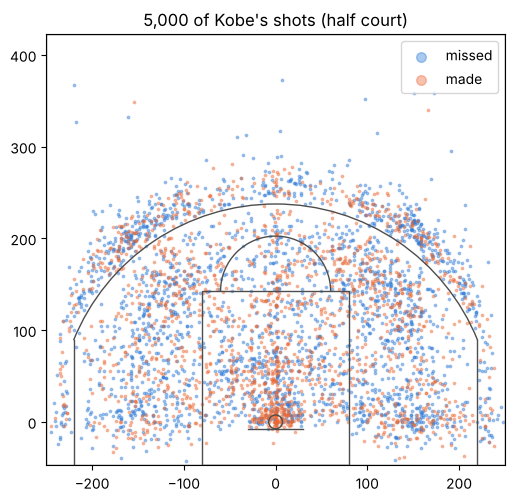

In [14]:
from matplotlib.patches import Arc, Circle, Rectangle


def draw_court(ax):
    # NBA half court in tenths of feet, rim at (0, 0)
    ink = dict(edgecolor="0.3", lw=1, fill=False)
    # rim and backboard
    ax.add_patch(Circle((0, 0), 7.5, **ink))
    ax.plot([-30, 30], [-7.5, -7.5], color="0.3", lw=1)
    # the paint and the free-throw circle
    ax.add_patch(Rectangle((-80, -47.5), 160, 190, **ink))
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=0, theta2=180, **ink))
    # three-point line: two corner segments and an arc of radius 23.75 ft
    ax.plot([-220, -220], [-47.5, 89.5], color="0.3", lw=1)
    ax.plot([220, 220], [-47.5, 89.5], color="0.3", lw=1)
    ax.add_patch(Arc((0, 0), 475, 475, theta1=22, theta2=158, **ink))
    # baseline, sidelines and the half-way line
    ax.add_patch(Rectangle((-250, -47.5), 500, 470, **ink))
    ax.set_xlim(-250, 250)
    ax.set_ylim(-47.5, 422.5)
    ax.set_aspect("equal")


shots = df.sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(6, 5.6))
for flag, color, label in [(0, "#2a78d6", "missed"), (1, "#eb6834", "made")]:
    subset = shots[shots["shot_made_flag"] == flag]
    ax.scatter(subset["loc_x"], subset["loc_y"], s=3, alpha=0.4, color=color,
               label=label)
draw_court(ax)
ax.legend(loc="upper right", markerscale=4)
ax.set_title("5,000 of Kobe's shots (half court)")
plt.show()

## Part 4 · Planned mistake 1: no input scaling

We feed the **raw** coordinates (hundreds) into a fresh 2-8-8-1 and look at the loss before any training.
A fresh net should start near ln 2 = 0.693 (Kobe's constant baseline is 0.686).

**PREDICT: what will happen?** Loss at init: (a) ≈ 0.69 (b) ≈ 2 (c) NaN (d) an error

In [15]:
# sigmoid + binary cross-entropy in one numerically safe step
loss_fn = nn.BCEWithLogitsLoss()

torch.manual_seed(0)
model = MLP()
with torch.no_grad():
    logits = model(X_tr)                   # RAW coordinates
print(f"loss at init, raw inputs: {loss_fn(logits, y_tr).item():.3f}")
print(f"what a fresh net should print: ln 2 = {math.log(2):.3f}")
print(f"logits range: {logits.min().item():.1f} to {logits.max().item():.1f}")

loss at init, raw inputs: 2.360
what a fresh net should print: ln 2 = 0.693
logits range: -37.8 to -0.1


Inputs in the hundreds → pre-activations in the hundreds → logits in the tens → the net is confidently wrong
from step 0. Fix: standardise each column with the **training** mean and std (LeCun 1998, "Efficient BackProp").
Validation and test data reuse the same two numbers.
Kobe task: the grader feeds raw coordinates, so in your submission the scaling must be folded into `fc1` (section 9).

Run the next cell **once**: a second run would measure mean 0 and std 1 on the already-scaled data,
and the court picture in part 5 needs the real `mu` and `sd`.

In [16]:
mu = X_tr.mean(0)            # from TRAIN only: one mean and one std per column
sd = X_tr.std(0)
X_tr = (X_tr - mu) / sd
X_va = (X_va - mu) / sd      # same mu, sd: never the validation set's own
print("train mean", mu, "  train std", sd)
print("scaled train mean", X_tr.mean(0), "  std", X_tr.std(0))

train mean tensor([ 6.5153, 91.6794])   train std tensor([110.0471,  88.1365])
scaled train mean tensor([2.1935e-08, 2.3460e-08])   std tensor([1.0000, 1.0000])


In [17]:
with torch.no_grad():
    logits = model(X_tr)                   # the same weights, scaled inputs
print(f"loss at init, scaled inputs: {loss_fn(logits, y_tr).item():.3f}")
print(f"logits range: {logits.min().item():.2f} to {logits.max().item():.2f}")

loss at init, scaled inputs: 0.691
logits range: -0.55 to -0.08


## Part 5 · The model and the training loop

Evaluation first: `model.eval()` + `torch.no_grad()`. A logit > 0 means p > 0.5, so that is the
"made" prediction; the log loss is the same `BCEWithLogitsLoss`. We print three numbers: loss,
accuracy and the share of shots predicted "made" (0 or 1 there means the model is a constant).

In [18]:
def evaluate(model, X, y):
    # test behaviour: matters for dropout / batch-norm, here it is a habit
    model.eval()
    # no graph: faster, less memory
    with torch.no_grad():
        logits = model(X)
        loss = loss_fn(logits, y).item()
        pred = (logits > 0).float()            # logit > 0  <=>  p > 0.5
        acc = (pred == y).float().mean().item()
    return loss, acc, pred.mean().item()       # loss, accuracy, share "made"


evaluate(model, X_va, y_va)                    # the untrained net from part 4

(0.6894713640213013, 0.5608000159263611, 0.0)

The last three lines of the setup slide: model, loss, optimizer.

In [19]:
torch.manual_seed(0)
model = MLP()                          # 2-8-8-1, 105 weights
loss_fn = nn.BCEWithLogitsLoss()       # takes logits: no sigmoid in the model
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

The loop from the slide. Two loops: epochs (every shot once) and batches of 64.
Every batch gets the five beats **zero_grad → forward → loss → backward → step**.
We also store the train and validation loss after each epoch, for the plot.

**PREDICT:** after 30 epochs (9,390 steps), will we beat the constant baseline 0.686? By how much? Accuracy?

In [20]:
history = []                                   # (train loss, val loss) per epoch
for epoch in range(30):
    model.train()                              # evaluate() set eval mode: switch back
    perm = torch.randperm(len(X_tr))           # a new shuffle every epoch
    for i in range(0, len(X_tr), 64):          # 313 batches of 64 shots
        idx = perm[i:i + 64]
        opt.zero_grad()                        # 1. clear the old gradients
        logits = model(X_tr[idx])              # 2. forward
        loss = loss_fn(logits, y_tr[idx])      # 3. loss
        loss.backward()                        # 4. backward: fills p.grad
        opt.step()                             # 5. step: update the weights
    train_loss = evaluate(model, X_tr, y_tr)[0]
    val_loss = evaluate(model, X_va, y_va)[0]
    history.append([train_loss, val_loss])
    print(epoch, loss.item())                  # the LAST batch only: it jumps around

0 0.674797773361206
1 0.6441755294799805


2 0.6067763566970825
3 0.6861893534660339


4 0.6419598460197449
5 0.6095313429832458


6 0.6694812774658203
7 0.6807165145874023


8 0.6900263428688049
9 0.6606300473213196


10 0.6750857830047607
11 0.6307104825973511


... (6 outputs left out)

23 0.7306426167488098
24 0.6509824395179749


25 0.7033594250679016
26 0.6504618525505066


27 0.7757751941680908
28 0.6923367381095886


29 0.6397765278816223


In [21]:
val_loss, val_acc, val_made = evaluate(model, X_va, y_va)
print(f"MLP 2-8-8-1: val log loss {val_loss:.4f}, val accuracy {val_acc:.1%}")
print(f"share of validation shots predicted 'made': {val_made:.1%}")

MLP 2-8-8-1: val log loss 0.6655, val accuracy 60.4%
share of validation shots predicted 'made': 34.8%


We will train seven more models today, so the same loop goes into a function.
It takes the data as arguments and returns the last batch's loss (the number the loop printed).

In [22]:
def train(model, opt, X, y, epochs=30):
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            opt.zero_grad()
            logits = model(X[idx])
            loss = loss_fn(logits, y[idx])
            loss.backward()
            opt.step()
    return loss.item()

Is 0.6655 good? Compare with two baselines: the constant prediction (every shot gets the training make rate)
and logistic regression, which is a network with no hidden layer: `nn.Linear(2, 1)`.

In [23]:
# constant: every shot gets the TRAINING make rate
p_const = torch.full_like(y_va, y_tr.mean().item())
const_loss = nn.functional.binary_cross_entropy(p_const, y_va).item()
const_acc = (y_va == 0).float().mean().item()          # 'always miss'

# logistic regression = one neuron, no hidden layer
torch.manual_seed(0)
logreg = nn.Linear(2, 1)
train(logreg, torch.optim.Adam(logreg.parameters(), lr=1e-3), X_tr, y_tr, epochs=10)
logreg_loss, logreg_acc, _ = evaluate(logreg, X_va, y_va)

names = [
    "constant / always miss",
    "logistic regression (3 params)",
    "MLP 2-8-8-1 (105 params)",
]
baselines = pd.DataFrame(
    {
        "val log loss": [const_loss, logreg_loss, val_loss],
        "val accuracy": [const_acc, logreg_acc, val_acc],
    },
    index=names,
)
baselines.round(4)

,val log loss,val accuracy
constant / always miss,0.6860,0.5608
logistic regression (3 params),0.6729,0.5882
MLP 2-8-8-1 (105 params),0.6655,0.6036


Small but real gains: typical for noisy human data. The loss curves:

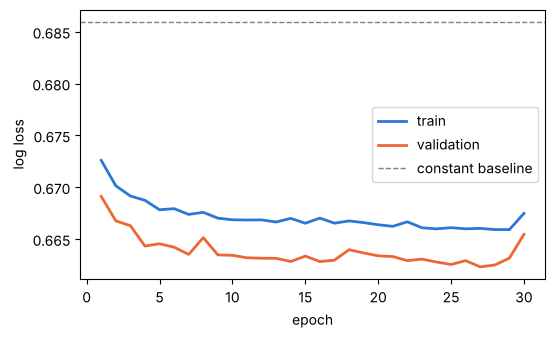

In [24]:
curves = pd.DataFrame(history, columns=["train loss", "val loss"], index=range(1, 31))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(curves.index, curves["train loss"], color="#2a78d6", lw=2, label="train")
ax.plot(curves.index, curves["val loss"], color="#eb6834", lw=2, label="validation")
ax.axhline(const_loss, color="0.5", ls="--", lw=1, label="constant baseline")
ax.set_xlabel("epoch")
ax.set_ylabel("log loss")
ax.legend()
plt.show()

What did it learn? Its probability at every point of the court (the orange line is p = 0.5):

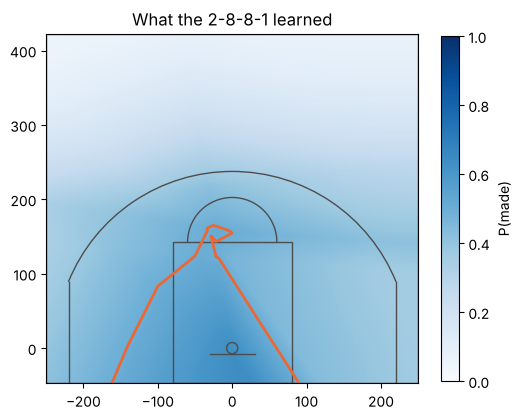

predicted probability ranges from 0.046 to 0.643


In [25]:
xs = torch.linspace(-250, 250, 251)
ys = torch.linspace(-47.5, 422.5, 236)
gx, gy = torch.meshgrid(xs, ys, indexing="xy")              # each (236, 251)
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)     # (59236, 2), raw

model.eval()
with torch.no_grad():
    # the same scaling as in training
    prob = torch.sigmoid(model((grid - mu) / sd)).view(gx.shape)

fig, ax = plt.subplots(figsize=(6, 5.6))
im = ax.imshow(prob, origin="lower", extent=(-250, 250, -47.5, 422.5),
               cmap="Blues", vmin=0, vmax=1)
ax.contour(gx, gy, prob, levels=[0.5], colors="#eb6834", linewidths=2)
draw_court(ax)
fig.colorbar(im, ax=ax, label="P(made)", shrink=0.8)
ax.set_title("What the 2-8-8-1 learned")
plt.show()
print(f"predicted probability ranges from {prob.min():.3f} to {prob.max():.3f}")

Its probabilities stay below about 65%: it is never confident. It predicts "made" (inside the orange
line) only close to the rim, because only there do more than half of his shots go in.

## Part 6 · Planned mistake 2: no `zero_grad`

The same loop with one line commented out.

**PREDICT: what will happen?** (1) crash (2) the same result (3) trains, but worse

In [26]:
torch.manual_seed(0)
model_nz = MLP()
opt = torch.optim.Adam(model_nz.parameters(), lr=1e-3)
for epoch in range(30):
    model_nz.train()
    perm = torch.randperm(len(X_tr))
    for i in range(0, len(X_tr), 64):
        idx = perm[i:i + 64]
        # opt.zero_grad()                      <- MISTAKE 2: deleted
        logits = model_nz(X_tr[idx])
        loss = loss_fn(logits, y_tr[idx])
        loss.backward()
        opt.step()

nz_loss, nz_acc, nz_made = evaluate(model_nz, X_va, y_va)
print(f"no zero_grad: val log loss {nz_loss:.4f}, accuracy {nz_acc:.1%}")
print(f"always miss:  val log loss {const_loss:.4f}, accuracy {const_acc:.1%}")
print(f"share of validation shots predicted 'made': {nz_made:.1%}")

no zero_grad: val log loss 0.7003, accuracy 43.9%
always miss:  val log loss 0.6860, accuracy 56.1%
share of validation shots predicted 'made': 100.0%


No error, no NaN, just a model worse than "always miss": it says "made" for every shot. A silent bug.
Why? `.grad` is a running **sum**:

In [27]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    loss = 2 * w
    loss.backward()
    print("w.grad =", w.grad.item())       # 2, 4, 6: every backward() ADDS to .grad

w.grad = 2.0
w.grad = 4.0
w.grad = 6.0


Without `zero_grad`, step k follows the sum of all k gradients so far, so the net keeps marching in old directions.

## Part 7 · Planned mistake 3: Sigmoid + `BCEWithLogitsLoss` (the cliffhanger)

Before the break you voted. Someone thinks "the output should be a probability" and changes the last line
of `forward` to `return torch.sigmoid(self.fc3(x))`, but keeps `BCEWithLogitsLoss`.

**PREDICT: what will happen?** (a) crash (b) normal (c) quietly worse (d) NaN. Re-vote now.

In [28]:
class MLPSigmoid(nn.Module):
    # a copy of MLP; only the last line of forward is different
    def __init__(self, hidden=8):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden)
        self.act1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden, hidden)
        self.act2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden, 1)

    def forward(self, x):
        x = self.act1(self.fc1(x))
        x = self.act2(self.fc2(x))
        return torch.sigmoid(self.fc3(x))      # <- MISTAKE 3


torch.manual_seed(0)
model_sig = MLPSigmoid()
opt = torch.optim.Adam(model_sig.parameters(), lr=1e-3)
last = train(model_sig, opt, X_tr, y_tr)       # loss_fn is still BCEWithLogitsLoss
print(f"printed loss of the last batch: {last:.4f}")

printed loss of the last batch: 0.6605


No crash, and the printed loss looks like a normal run. Its author treats the outputs as probabilities, so accuracy means p > 0.5:

In [29]:
model_sig.eval()
with torch.no_grad():
    p_sig = model_sig(X_va)                    # what this model calls probabilities
acc_sig = ((p_sig > 0.5).float() == y_va).float().mean()
print(f"printed val loss {loss_fn(p_sig, y_va).item():.4f},  accuracy {acc_sig:.1%}")
print(f"correct model:   {val_loss:.4f},  accuracy {val_acc:.1%}")

printed val loss 0.6845,  accuracy 61.7%
correct model:   0.6655,  accuracy 60.4%


Looks fine. Now the **real** log loss of those probabilities, the number any grader would compute.
−log 0 is infinite, so every log-loss function first clips p into [ε, 1 − ε]. We clip at ε = 1e-7.

In [30]:
with torch.no_grad():
    p_good = torch.sigmoid(model(X_va))        # the correct model from part 5

# clip, then the ordinary binary cross-entropy on probabilities
eps = 1e-7
real_sig = nn.functional.binary_cross_entropy(p_sig.clamp(eps, 1 - eps), y_va)
real_good = nn.functional.binary_cross_entropy(p_good.clamp(eps, 1 - eps), y_va)
print(f"real log loss:  sigmoid bug {real_sig.item():.3f}"
      f"   correct {real_good.item():.3f}")

real log loss:  sigmoid bug 4.532   correct 0.665


The exact size of that number depends on ε. These counts do not:

In [31]:
made = y_va == 1
low = p_sig < 0.01
print(f"made shots the bug model gave < 1%: {(made & low).sum().item()}"
      f" of {made.sum().item()} made shots")
print(f"outputs < 0.01:  sigmoid bug {(p_sig < 0.01).float().mean():.1%}"
      f"   correct {(p_good < 0.01).float().mean():.1%}")
print(f"outputs > 0.99:  sigmoid bug {(p_sig > 0.99).float().mean():.1%}"
      f"   correct {(p_good > 0.99).float().mean():.1%}")
print(f"outputs < 1e-7:  sigmoid bug {(p_sig < 1e-7).float().mean():.1%}")
print(f"largest output:  sigmoid bug {p_sig.max():.3f}   correct {p_good.max():.3f}")

made shots the bug model gave < 1%: 1453 of 2196 made shots
outputs < 0.01:  sigmoid bug 75.9%   correct 0.1%
outputs > 0.99:  sigmoid bug 0.0%   correct 0.0%
outputs < 1e-7:  sigmoid bug 60.9%
largest output:  sigmoid bug 0.619   correct 0.639


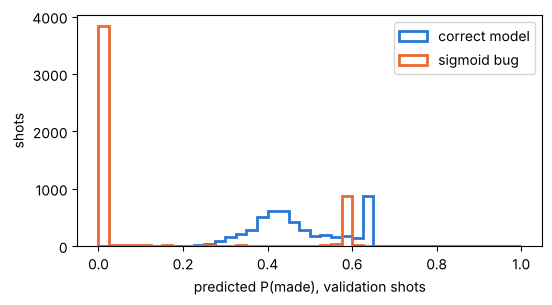

In [32]:
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 1, 41)
ax.hist(p_good.ravel(), bins=bins, histtype="step", lw=2, color="#2a78d6",
        label="correct model")
ax.hist(p_sig.ravel(), bins=bins, histtype="step", lw=2, color="#eb6834",
        label="sigmoid bug")
ax.set_xlabel("predicted P(made), validation shots")
ax.set_ylabel("shots")
ax.legend()
plt.show()

Why: `BCEWithLogitsLoss` applies **another** sigmoid. The model's output p is already in (0, 1), so the loss only ever sees σ(p):

In [33]:
# the 'probability' the loss sees is stuck in (0.5, 0.73)
torch.sigmoid(torch.tensor([0.0, 1.0]))

tensor([0.5000, 0.7311])

And the small bump on the right of the histogram? Look at what the loss sees there:

In [34]:
bump = p_sig > 0.3                             # the bump at about 0.55
print(f"shots in the bump: {bump.float().mean():.1%} of validation")
print(f"model output p:              {p_sig[bump].mean():.3f}")
print(f"what the loss sees, sig(p):  {torch.sigmoid(p_sig[bump]).mean():.3f}")
print(f"real make rate of these shots: {y_va[bump].mean():.3f}")

shots in the bump: 20.5% of validation
model output p:              0.568
what the loss sees, sig(p):  0.638
real make rate of these shots: 0.648


So, region by region:

* Where Kobe makes **fewer than half** of his shots (most of the court), the best the loss can see is
  σ(p) → 0.5, so the model pushes p towards 0: 76% of its outputs are below 1%, and 61% are below 1e-7.
* Where he makes **more than half** (near the rim), the loss is lowest when σ(p) equals the make rate,
  so p settles near logit(make rate): σ(p) = 0.64 against a real make rate of 0.65, which puts p at about 0.57.
  That is the bump. Nothing ever goes near 1.
* The printed loss is trapped: a made shot costs at least −log σ(1) = 0.313 and a miss at least
  −log(1 − σ(0)) = 0.693, so it always looks like "about 0.69".
* Accuracy at 0.5 survives by luck: the bump sits above 0.5 only because the rim make rate is above
  σ(0.5) = 0.62. A zone where he made 55% would get p = logit(0.55) ≈ 0.2 and be called a miss.
* The real log loss explodes on the made shots away from the rim: each one with p below 1e-7 costs
  −log(1e-7) ≈ 16. A smaller clip gives an even bigger number (sklearn's `log_loss` on a float64 array
  clips at 2.2e-16 and reports about 7.5 here); the verdict is the same.

Karpathy's mistake #4: "you passed softmaxed outputs to a loss that expects raw logits".
**Fix:** either logits + `BCEWithLogitsLoss` (what we do), or `nn.Sigmoid()` + `nn.BCELoss` (the Kobe baseline's head).
Never both sigmoids.

## Part 8 · Planned mistake 4: target shape `(N,)` vs `(N, 1)`

**PREDICT: what will happen?** I build the targets again **without** `.unsqueeze(1)`, so they are `(N,)`
while the model outputs `(N, 1)`. With `BCEWithLogitsLoss`? With `MSELoss`?

In [35]:
# MISTAKE 4: the targets again, WITHOUT .unsqueeze(1)
y_flat = torch.tensor(df["shot_made_flag"].values, dtype=torch.float32)
logits = model(X_tr[:64])                      # one batch of outputs: (64, 1)
yb = y_flat[tr][:64]                           # the same batch of targets: (64,)
print(logits.shape, yb.shape)
# try/except only so that "Run all" does not stop here
try:
    loss_fn(logits, yb)
except ValueError as err:
    print("ValueError:", err)

torch.Size([64, 1]) torch.Size([64])
ValueError: Target size (torch.Size([64])) must be the same as input size (torch.Size([64, 1]))


A loud error: read the message aloud, it says exactly what is wrong. `MSELoss` is quieter:

In [36]:
pred = torch.tensor([[1.0], [2.0], [3.0]])     # (3, 1): a PERFECT prediction ...
truth = torch.tensor([1.0, 2.0, 3.0])          # (3,)
print("MSE:", nn.MSELoss()(pred, truth).item())        # ... so this should be 0
# broadcasting: every prediction minus every target, a 3 x 3 table
print("pred - truth has shape", (pred - truth).shape)
print((pred - truth) ** 2)
print("fixed:", nn.MSELoss()(pred.squeeze(1), truth).item())

MSE: 1.3333333730697632
pred - truth has shape torch.Size([3, 3])
tensor([[0., 1., 4.],
        [1., 0., 1.],
        [4., 1., 0.]])
fixed: 0.0


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([3])) that is different to the input size (torch.Size([3, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Only a warning, and a wrong number: the average of all 9 squares is 12 / 9 = 1.33. Fix: `y.unsqueeze(1)`
(or `y.view(-1, 1)`), and print `logits.shape` and `y.shape` once before training.
This matters for the inversion task: `model(X)` returns `(1000, 1)` and `y` is `(1000,)`.
The `.squeeze()` in the starter code is what prevents a silent 1000 × 1000 loss.

## Part 9 · Optimizer comparison on Kobe

The same net, the same seed, 30 epochs; only the optimizer and its learning rate change.

**PREDICT (P8, P10):** rank SGD lr 1e-3, SGD lr 0.1, Adam lr 1e-3 and Adam lr 1.0.
Which ones end up no better than the constant baseline?

In [37]:
configs = [
    (torch.optim.SGD, 1e-3),
    (torch.optim.SGD, 0.1),
    (torch.optim.Adam, 1e-3),
    (torch.optim.Adam, 1.0),
]
rows = []
for opt_class, lr in configs:
    torch.manual_seed(0)
    m = MLP()
    train(m, opt_class(m.parameters(), lr=lr), X_tr, y_tr)
    loss, acc, share_made = evaluate(m, X_va, y_va)
    rows.append([opt_class.__name__, lr, loss, acc, share_made])

columns = ["optimizer", "lr", "val log loss", "val accuracy", "share 'made'"]
pd.DataFrame(rows, columns=columns).round(4)

,optimizer,lr,val log loss,val accuracy,share 'made'
0,SGD,0.001,0.6810,0.5608,0.0000
1,SGD,0.100,0.6631,0.6102,0.2790
2,Adam,0.001,0.6655,0.6036,0.3476
3,Adam,1.000,0.6885,0.5608,0.0000


* SGD 1e-3 barely moves in 9,390 steps: it still says "miss" for every shot.
* SGD 0.1 is as good as Adam (here even a little better): tuned SGD is fine.
* Adam 1.0 jumps around and ends at "always miss", with a log loss worse than the constant.
* Adam 1e-3 reproduces part 5 exactly: same seed, same numbers.
* lr 1e-3 is an Adam default, not a law of nature: sweep 3e-4, 1e-3, 3e-3, 1e-2 and pick by validation loss.

## Part 10 · Overfitting and early stopping

Overfitting needs a big model and little data: a 2-256-256-1 trained on only **500** shots, full batch, Adam 1e-3,
2000 steps. Validation is the usual 5,000 shots.

**PREDICT:** sketch the train and validation loss curves.

In [38]:
torch.manual_seed(0)
few = torch.randperm(len(X_tr))[:500]
X_few = X_tr[few]
y_few = y_tr[few]

big = MLP(hidden=256)
print("parameters:", sum(p.numel() for p in big.parameters()), "(the Kobe net has 105)")

parameters: 66817 (the Kobe net has 105)


In [39]:
import copy

opt = torch.optim.Adam(big.parameters(), lr=1e-3)
big_curve = []
best_val = float("inf")
for step in range(1, 2001):
    big.train()
    opt.zero_grad()
    loss = loss_fn(big(X_few), y_few)          # full batch: all 500 shots every step
    loss.backward()
    opt.step()
    if step % 10 == 0:
        val = evaluate(big, X_va, y_va)[0]
        big_curve.append([step, loss.item(), val])
        # early stopping: remember the best weights so far
        if val < best_val:
            best_val = val
            best_step = step
            # deepcopy! state_dict() alone shares memory with the live weights
            best_state = copy.deepcopy(big.state_dict())

big_curve = pd.DataFrame(big_curve, columns=["step", "train loss", "val loss"])
big_curve = big_curve.set_index("step")
big_curve.loc[[10, 100, 300, 1000, 2000]].round(3)

,train loss,val loss
step,,
10,0.669,0.678
100,0.627,0.717
300,0.560,0.795
1000,0.458,1.025
2000,0.387,1.352


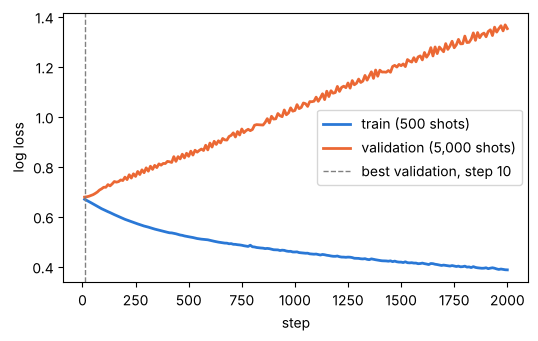

In [40]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(big_curve.index, big_curve["train loss"], color="#2a78d6", lw=2,
        label="train (500 shots)")
ax.plot(big_curve.index, big_curve["val loss"], color="#eb6834", lw=2,
        label="validation (5,000 shots)")
ax.axvline(best_step, color="0.5", ls="--", lw=1,
           label=f"best validation, step {best_step}")
ax.set_xlabel("step")
ax.set_ylabel("log loss")
ax.legend()
plt.show()

In [41]:
last_loss, last_acc, _ = evaluate(big, X_va, y_va)
big.load_state_dict(best_state)                # roll back to the best checkpoint
best_loss, best_acc, _ = evaluate(big, X_va, y_va)
print(f"last weights (step 2000): val log loss {last_loss:.4f},"
      f" accuracy {last_acc:.1%}")
print(f"best weights (step {best_step}):   val log loss {best_loss:.4f},"
      f" accuracy {best_acc:.1%}")
print(f"the 105-parameter net (part 5): val log loss {val_loss:.4f}")

last weights (step 2000): val log loss 1.3518, accuracy 56.3%
best weights (step 10):   val log loss 0.6779, accuracy 57.0%
the 105-parameter net (part 5): val log loss 0.6655


Train loss keeps falling while validation loss climbs: the net memorises 500 noisy shots.
On this data it starts memorising almost at once, so the best checkpoint is one of the first.
(The slide shows 1.23, the mean of three seeds on the Kaggle file; this single run ends higher, same story.)

Two honest remarks:
* The "best weights" score is slightly optimistic: we picked the step **because** it was best on this
  validation set. Report a held-out test set once, at the very end; never tune on it.
* Even the best checkpoint of the 66,817-parameter net is worse than the 105-parameter net from part 5.

Cures: more data · a smaller model · weight decay · dropout · early stopping with the best checkpoint.
(Real early stopping also `break`s once validation has not improved for, say, 20 checks; we kept going only to draw the curve.)
For the 105-parameter Kobe net, overfitting is not the problem; optimisation is.

## Part 11 · Optimise the input, not the weights (bridge to the inversion task)

Training: the data is fixed and the weights move. Inversion: the model is frozen and an **input** moves.
The tools are the same: `requires_grad` on the unknown, a loss, an optimizer.
Toy model: f(a, b, c) = a + 2b + c². We know a = 1, c = 1.5 and the output y; recover b.

In [42]:
def f(a, b, c):
    # a frozen "model": we may only change what we feed it
    return a + 2 * b + c ** 2


a, c = 1.0, 1.5
y_seen = f(a, 0.7, c)                          # the true b is 0.7; now we only know y
b = torch.tensor(0.0, requires_grad=True)      # the unknown input is what we optimise
opt = torch.optim.SGD([b], lr=0.1)
for step in range(30):
    opt.zero_grad()
    loss = (f(a, b, c) - y_seen) ** 2
    loss.backward()
    opt.step()
print(f"y = {y_seen:.2f}   recovered b = {b.item():.4f}   loss = {loss.item():.1e}")

y = 4.65   recovered b = 0.7000   loss = 0.0e+00


**PREDICT:** the same with lr 0.125, 0.25 and 0.3?

In [43]:
for lr in [0.125, 0.25, 0.3]:
    b = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.SGD([b], lr=lr)
    path = []
    for step in range(6):
        opt.zero_grad()
        loss = (f(a, b, c) - y_seen) ** 2
        loss.backward()
        opt.step()
        path.append(round(b.item(), 3))
    print(f"lr {lr:<5}  b: {path}")

lr 0.125  b: [0.7, 0.7, 0.7, 0.7, 0.7, 0.7]
lr 0.25   b: [1.4, 0.0, 1.4, 0.0, 1.4, 0.0]
lr 0.3    b: [1.68, -0.672, 2.621, -1.989, 4.465, -4.571]


One step (lr = 1/8 is exactly Newton here) · bouncing forever · blowing up. The task has a whole column of
1,000 unknowns: one tensor, all rows at once. Adam moves each unknown by about lr per step, so lr 1e-3 is far
too slow for inputs of size ~1.

In [44]:
torch.manual_seed(0)
a_col = torch.randn(1000)
c_col = torch.randn(1000)
b_true = torch.randn(1000)                     # the column overwritten with 0.0
y_col = f(a_col, b_true, c_col)                # the frozen model's outputs: known

for lr in [1e-3, 0.1]:
    # start from the zeros in the file
    b_hat = torch.zeros(1000, requires_grad=True)
    opt = torch.optim.Adam([b_hat], lr=lr)
    for step in range(300):
        opt.zero_grad()
        # (1000,) vs (1000,): no broadcasting trap
        loss = ((f(a_col, b_hat, c_col) - y_col) ** 2).mean()
        loss.backward()
        opt.step()
    mse = ((b_hat - b_true) ** 2).mean().item()
    print(f"Adam lr {lr:<5}  300 steps:  MSE(recovered b, true b) = {mse:.4f}")

Adam lr 0.001  300 steps:  MSE(recovered b, true b) = 0.5656
Adam lr 0.1    300 steps:  MSE(recovered b, true b) = 0.0000


Not every unknown is this easy. If **c** is the missing input, c² = 2.25 has two answers:

In [45]:
for start in [0.1, -0.1, 0.0]:
    c_hat = torch.tensor(start, requires_grad=True)
    opt = torch.optim.SGD([c_hat], lr=0.05)
    for step in range(200):
        opt.zero_grad()
        loss = (f(a, 0.7, c_hat) - y_seen) ** 2
        loss.backward()
        opt.step()
    print(f"start {start:+.1f}  ->  c = {c_hat.item():+.4f}")

start +0.1  ->  c = +1.5000


start -0.1  ->  c = -1.5000


start +0.0  ->  c = +0.0000


The start decides which root you get, and starting exactly at 0 gets stuck: the gradient there is exactly 0.
In the real task: freeze the model with `model.eval()` **and**
`for p in model.parameters(): p.requires_grad_(False)` (`eval()` alone only switches dropout and
batch-norm behaviour; it does not freeze anything), give the optimizer only the missing column,
use `torch.cat` to rebuild the input, mind the `(1000, 1)` vs `(1000,)` shapes, and check the residual.

**Pre-flight checklist for both tasks:** seed · scale inputs with train statistics · loss at init ≈ 0.69 ·
baselines first · validation split · logits + `BCEWithLogitsLoss` · `zero_grad` · target shapes ·
Adam 1e-3, then sweep the lr · keep the best weights · assert the parameter count (≤ 105) ·
**Kobe export:** train on logits, but end `MyModel` with `nn.Sigmoid()` (the grader most likely thresholds
the output at 0.5) and fold the scaling into `fc1`.